$$Source/SInk$$


In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
x = np.linspace(-5,5,200)
y = np.linspace(-5,5,200)

X,Y = np.meshgrid(x,y)

In [20]:
def source(X,Y,coords, Q=1.0):
    X= X-coords[0]
    Y=Y-coords[1]
    r2 = np.maximum((X**2 + Y**2),1e-8)
    u = Q/(np.pi*2)*(X/r2)
    v = Q/(np.pi*2)*(Y/r2)

    return u,v

def uniform(u):
    return u

<function matplotlib.pyplot.show(close=None, block=None)>

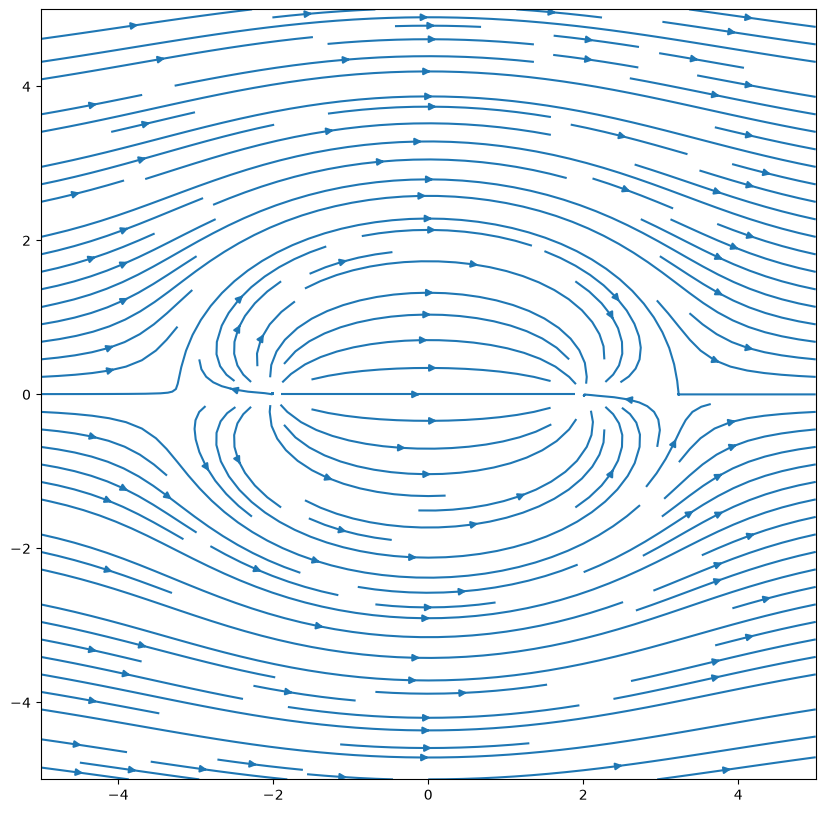

In [25]:
U1,V1 = source(X,Y,[-2,0])
U2,V2 = source(X,Y,[2,0],-1)
u = uniform(0.1)
U,V = U1+U2+u, V1+V2

plt.figure(figsize=(10,10))
plt.streamplot(X,Y,U,V, density = 1.5)
plt.show

AI for Prettier Visualization


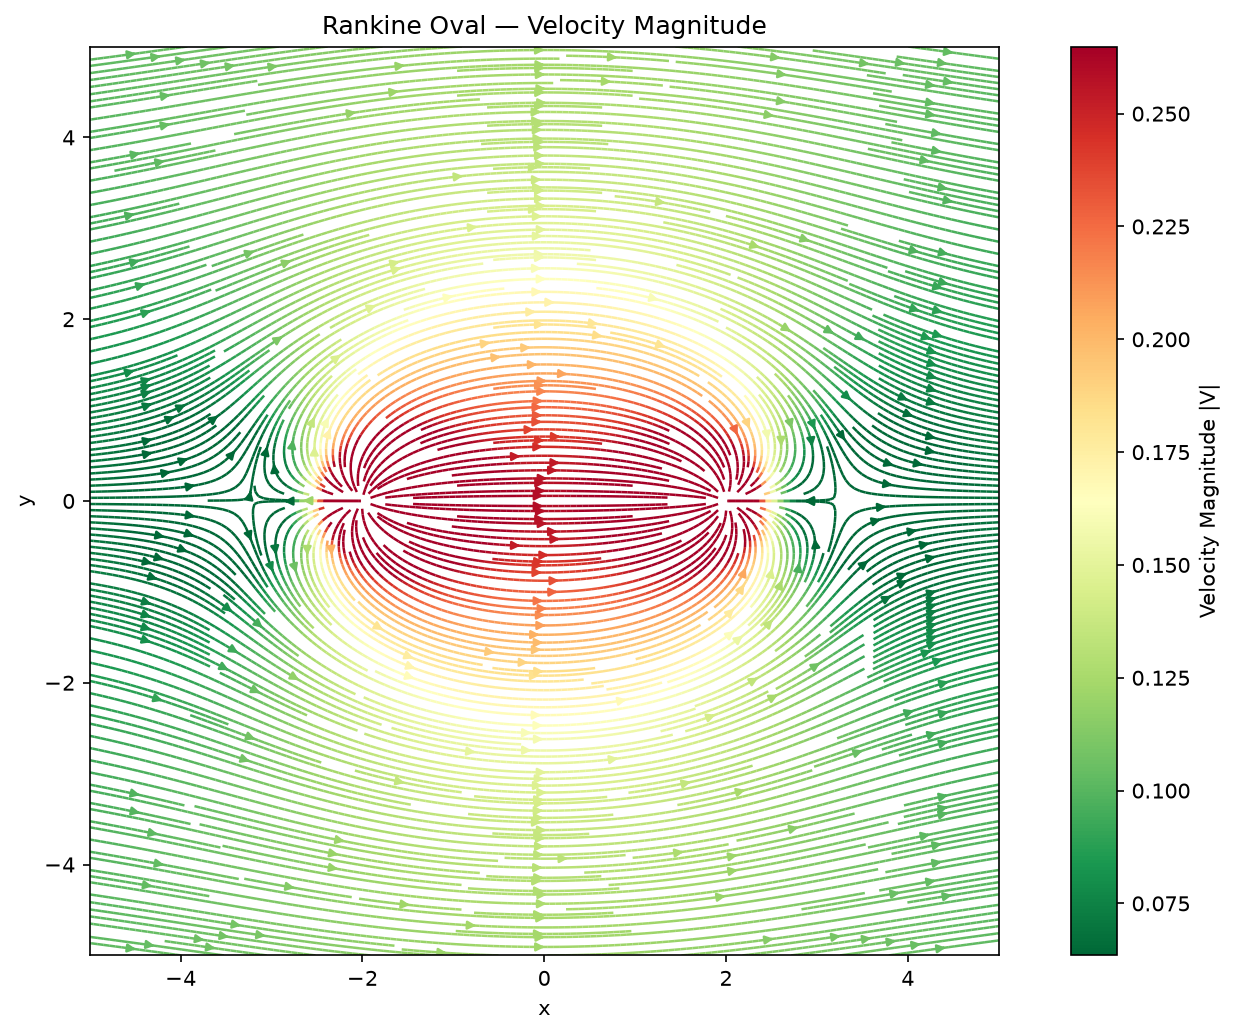

In [30]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import Normalize

# Calculate velocity magnitude (speed) at every grid point
speed = np.sqrt(U**2 + V**2)

# Clip the colour scale to reduce the influence of extreme velocities
vmin = np.percentile(speed, 5)
vmax = np.percentile(speed, 95)
norm = Normalize(vmin=vmin, vmax=vmax)

fig, ax = plt.subplots(figsize=(10, 7), dpi=150)

# Colour streamlines according to local speed
stream = ax.streamplot(
    X, Y, U, V,
    color=speed,
    cmap="RdYlGn_r",
    norm=norm,
    density=5,
    linewidth=1.2,
    arrowsize=0.8
)

# Add a colour bar
cbar = fig.colorbar(stream.lines, ax=ax)
cbar.set_label("Velocity Magnitude |V|")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Rankine Oval — Velocity Magnitude")
ax.set_aspect("equal")
ax.set_xlim(-5, 5)
ax.set_ylim(-5, 5)

plt.tight_layout()
plt.show()
